# 05 — Fine-tuned ResNet-18 (Model B)

This notebook launches the project study-level fine-tuning implementation. Each study can include several views. Real views are aggregated at study level and padded views are masked.

Only the internal train and validation populations are used. The official MURA valid split is not read.

In [1]:
import json
import os
import subprocess
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

## Project and data paths

In [2]:
try:
    from google.colab import drive
    drive.mount("/content/drive")
except ModuleNotFoundError:
    pass

PROJECT_ROOT = Path(os.environ.get(
    "MURA_PROJECT_ROOT",
    "/content/drive/MyDrive/MURA_PROJECT/mura-wrist-ml-pipeline",
))
RUN_MODE = os.environ.get("MURA_MODEL_B_RUN_MODE", "verify_existing")
if RUN_MODE not in {"verify_existing", "train_new_experiment"}:
    raise ValueError("MURA_MODEL_B_RUN_MODE must be 'verify_existing' or 'train_new_experiment'")

DATA_ROOT = Path(os.environ.get(
    "MURA_DATA_ROOT",
    "/content/drive/MyDrive/DATA/MURA-v1.1",
))
PREPROCESSING_DIR = Path(os.environ.get(
    "MURA_PREPROCESSING_DIR",
    "/content/drive/MyDrive/DATA/PREPROCESSED_WRIST",
))
ARTIFACT_DIR = Path(os.environ.get(
    "MURA_MODEL_B_DIR",
    "/content/drive/MyDrive/DATA/MODEL_B_FINE_TUNING",
))
ARTIFACT_DIR.mkdir(parents=True, exist_ok=True)

MODEL_B_INPUT_DIR = ARTIFACT_DIR / "model_b_input"
MODEL_B_INPUT_DIR.mkdir(parents=True, exist_ok=True)
TRAIN_SCRIPT = PROJECT_ROOT / "scripts/train_resnet18.py"
BUNDLE_SPEC = PROJECT_ROOT / "configs" / "model_b_artifact_bundle.json"
BUNDLE_VERIFIER = PROJECT_ROOT / "scripts" / "verify_model_artifact_bundle.py"
BUNDLE_REASSEMBLER = PROJECT_ROOT / "scripts" / "reassemble_model_b_checkpoint.py"
for required_path in (
    PREPROCESSING_DIR / "wrist_internal_train_clean.csv",
    PREPROCESSING_DIR / "wrist_internal_val_clean.csv",
    TRAIN_SCRIPT,
    BUNDLE_SPEC,
    BUNDLE_VERIFIER,
    BUNDLE_REASSEMBLER,
    DATA_ROOT / "train",
):
    assert required_path.exists(), f"Not found: {required_path}"

print({
    "project_root_available": PROJECT_ROOT.exists(),
    "data_root_available": DATA_ROOT.exists(),
    "artifact_directory_ready": ARTIFACT_DIR.exists(),
    "run_mode": RUN_MODE,
})

{'project_root_available': True, 'data_root_available': True, 'artifact_directory_ready': True, 'run_mode': 'verify_existing'}


## Build Model B inputs from the cleaned Model A split

In [3]:
train_clean = pd.read_csv(PREPROCESSING_DIR / "wrist_internal_train_clean.csv")
validation_clean = pd.read_csv(PREPROCESSING_DIR / "wrist_internal_val_clean.csv")
PATH_CANDIDATES = ("file_name", "image_path", "relative_path", "path")
PATH_COLUMN = next((name for name in PATH_CANDIDATES if name in train_clean.columns), None)
assert PATH_COLUMN is not None and PATH_COLUMN in validation_clean.columns

def make_model_b_rows(frame, final_split):
    result = frame[["patient_id", "study_uid", PATH_COLUMN, "label_binary"]].copy()
    result["image_path"] = result[PATH_COLUMN].astype(str).str.replace("\\", "/", regex=False)
    result["image_path"] = result["image_path"].str.split("MURA-v1.1/", n=1).str[-1]
    result = result.rename(columns={"study_uid": "study_id", "label_binary": "label"})
    result["source_split"] = "train"
    result["final_split"] = final_split
    result["num_views_in_study"] = result.groupby("study_id")["image_path"].transform("size")
    return result[["patient_id", "study_id", "image_path", "label", "source_split", "num_views_in_study", "final_split"]]

model_b_rows = pd.concat([
    make_model_b_rows(train_clean, "train"),
    make_model_b_rows(validation_clean, "val"),
], ignore_index=True)
assert model_b_rows.groupby("study_id")["label"].nunique().max() == 1
assert set(model_b_rows.loc[model_b_rows.final_split.eq("train"), "patient_id"]).isdisjoint(
    set(model_b_rows.loc[model_b_rows.final_split.eq("val"), "patient_id"])
)

MODEL_B_MANIFEST = MODEL_B_INPUT_DIR / "wrist_clean_manifest.csv"
MODEL_B_SPLIT = MODEL_B_INPUT_DIR / "wrist_clean_split_manifest.csv"
model_b_rows.drop(columns="final_split").to_csv(MODEL_B_MANIFEST, index=False)
model_b_rows[["patient_id", "study_id", "final_split"]].drop_duplicates().to_csv(MODEL_B_SPLIT, index=False)
print({"train_studies": int((model_b_rows.final_split == "train").groupby(model_b_rows.study_id).max().sum()), "validation_studies": int((model_b_rows.final_split == "val").groupby(model_b_rows.study_id).max().sum())})

{'train_studies': 2769, 'validation_studies': 691}

## Frozen training recipe

In [4]:
TRAINING_RECIPE = {
    "architecture": "ImageNet ResNet-18 with one logit per view",
    "loss": "weighted BCE on the study-level mean probability",
    "train_split": "internal patient-level train",
    "validation_split": "internal patient-level validation",
    "official_valid_access": False,
    "epochs": 15,
    "batch_size_studies": 2,
    "learning_rate": 1e-4,
    "weight_decay": 1e-4,
    "early_stopping": "validation study AUROC, patience 4",
    "preprocessing": "grayscale, square black padding, 224x224 bilinear resize, ImageNet normalization",
    "augmentation": "rotation up to 7 degrees, brightness 0.08, contrast 0.10; no horizontal flip or crop",
    "primary_aggregation": "mean probability (pre-specified before training)",
    "secondary_aggregation": "max probability (diagnostic only; not selected post hoc)",
    "operating_policy": "highest validation threshold with sensitivity >= 95%",
}
display(pd.DataFrame([TRAINING_RECIPE]))


,architecture,loss,train_split,validation_split,official_valid_access,epochs,batch_size_studies,learning_rate,weight_decay,early_stopping,preprocessing,augmentation,primary_aggregation,secondary_aggregation,operating_policy
0,ImageNet ResNet-18 with one logit per view,weighted BCE on the study-level mean probability,internal patient-level train,internal patient-level validation,False,15,2,0.0001,0.0001,"validation study AUROC, patience 4","grayscale, square black padding, 224x224 bilin...","rotation up to 7 degrees, brightness 0.08, con...",mean probability (pre-specified before training),max probability (diagnostic only; not selected...,highest validation threshold with sensitivity ...


## Run fine-tuning without test access

In [5]:
command = [
    sys.executable,
    str(TRAIN_SCRIPT),
    "--manifest", str(MODEL_B_MANIFEST),
    "--split-manifest", str(MODEL_B_SPLIT),
    "--dataset-root", str(DATA_ROOT),
    "--output-dir", str(ARTIFACT_DIR),
    "--epochs", "15",
    "--batch-size", "2",
    "--workers", "0",
    "--learning-rate", "1e-4",
    "--weight-decay", "1e-4",
    "--early-stopping-patience", "4",
    "--seed", "42",
    "--device", "auto",
    "--weights", "imagenet",
    "--class-weighting", "auto",
    "--monitor-metric", "auroc",
    "--train-aggregation", "mean",
    "--monitor-aggregation", "mean",
    "--sensitivity-target", "0.95",
    "--scheduler", "plateau",
    "--bootstrap-samples", "1000",
]
print("Model B run policy: use the verified canonical bundle by default.")
CHECKPOINT_PATH = ARTIFACT_DIR / 'best_resnet18_study_level.pt'
CHECKPOINT_PARTS_DIR = ARTIFACT_DIR / 'checkpoint_parts'
if not CHECKPOINT_PATH.exists() and (CHECKPOINT_PARTS_DIR / 'checkpoint_parts.json').is_file():
    reconstruction = subprocess.run(
        [sys.executable, str(BUNDLE_REASSEMBLER), '--parts-dir', str(CHECKPOINT_PARTS_DIR), '--output-dir', str(ARTIFACT_DIR)],
        check=True, capture_output=True, text=True,
    )
    print({'checkpoint_reassembly': json.loads(reconstruction.stdout)['status']})
required_outputs = [
    ARTIFACT_DIR / 'best_resnet18_study_level.pt',
    ARTIFACT_DIR / 'training_history.json',
    ARTIFACT_DIR / 'validation_metrics.json',
    ARTIFACT_DIR / 'validation_predictions.csv',
    ARTIFACT_DIR / 'validation_predictions_mean.csv',
    ARTIFACT_DIR / 'validation_predictions_max.csv',
    ARTIFACT_DIR / 'selection.json',
    ARTIFACT_DIR / 'frozen_primary_operating_policy.json',
]
missing_outputs = [path.name for path in required_outputs if not path.exists()]
if not missing_outputs:
    verification = subprocess.run(
        [sys.executable, str(BUNDLE_VERIFIER), '--artifact-dir', str(ARTIFACT_DIR), '--bundle-spec', str(BUNDLE_SPEC)],
        check=True, capture_output=True, text=True,
    )
    bundle_summary = json.loads(verification.stdout)
    print({
        'fine_tuning_completed': True,
        'canonical_bundle_verified': True,
        'selected_threshold': bundle_summary['threshold'],
        'target_sensitivity': bundle_summary['target_sensitivity'],
        'checkpoint_sha256_prefix': bundle_summary['checkpoint_sha256'][:12],
    })
elif RUN_MODE == 'verify_existing':
    raise FileNotFoundError(
        'Canonical Model B artifacts are missing: ' + ', '.join(missing_outputs) + '. ' 
        'If checkpoint_parts/ is present, run reassemble_model_b_checkpoint.py first; ' 
        'this notebook will not silently train a replacement model.'
    )
else:
    if ARTIFACT_DIR.name == 'MODEL_B_FINE_TUNING':
        raise RuntimeError(
            'A new experiment must use a separate, clearly named artifact directory; ' 
            'do not overwrite the canonical MODEL_B_FINE_TUNING bundle.'
        )
    if any(ARTIFACT_DIR.iterdir()):
        raise RuntimeError('The new experiment directory must be empty before training starts.')
    print('Starting a separately named controlled experiment on internal train/validation only.')
    completed = subprocess.run(
        command, cwd=PROJECT_ROOT, check=True, capture_output=True, text=True
    )
    print({'fine_tuning_completed': completed.returncode == 0})

Model B run policy: use the verified canonical bundle by default.


{'fine_tuning_completed': True, 'canonical_bundle_verified': True, 'selected_threshold': 0.263567715883255, 'target_sensitivity': 0.95, 'checkpoint_sha256_prefix': '63AEDC6BEC15'}


## Inspect saved development artifacts

In [6]:
required_outputs = [
    "best_resnet18_study_level.pt",
    "training_history.json",
    "validation_metrics.json",
    "validation_predictions.csv",
    "validation_predictions_mean.csv",
    "validation_predictions_max.csv",
    "selection.json",
    "run_config.json",
]
for name in required_outputs:
    assert (ARTIFACT_DIR / name).exists(), f"Training did not produce: {name}"

history = json.loads((ARTIFACT_DIR / "training_history.json").read_text(encoding="utf-8"))
validation_metrics = json.loads((ARTIFACT_DIR / "validation_metrics.json").read_text(encoding="utf-8"))
selection = json.loads((ARTIFACT_DIR / "selection.json").read_text(encoding="utf-8"))
run_config = json.loads((ARTIFACT_DIR / "run_config.json").read_text(encoding="utf-8"))
validation_predictions = pd.read_csv(ARTIFACT_DIR / "validation_predictions.csv")
if 'split' not in validation_predictions.columns:
    validation_predictions['split'] = 'validation'

assert run_config["arguments"]["write_test_predictions"] is False
assert selection["test_used_for_selection"] is False
assert selection["selection_data"] == "validation only"
assert validation_predictions["split"].eq("validation").all()
assert validation_predictions["study_id"].is_unique

# This saved checkpoint predates the 95% protocol update. Reuse its saved mean-pooled
# validation probabilities, but do not reuse its historical Youden-J threshold.
PRIMARY_SENSITIVITY_TARGET = 0.95
policy_rows = []
labels = validation_predictions["label"].to_numpy(dtype=int)
scores = validation_predictions["abnormal_probability"].to_numpy(dtype=float)
for threshold in np.unique(scores)[::-1]:
    predicted = scores >= threshold
    true_positive = int(((labels == 1) & predicted).sum())
    false_negative = int(((labels == 1) & ~predicted).sum())
    true_negative = int(((labels == 0) & ~predicted).sum())
    false_positive = int(((labels == 0) & predicted).sum())
    sensitivity = true_positive / (true_positive + false_negative)
    if sensitivity >= PRIMARY_SENSITIVITY_TARGET:
        policy_rows.append({
            "threshold": float(threshold),
            "sensitivity": float(sensitivity),
            "specificity": float(true_negative / (true_negative + false_positive)),
            "true_positive": true_positive,
            "false_negative": false_negative,
            "true_negative": true_negative,
            "false_positive": false_positive,
        })

if not policy_rows:
    raise RuntimeError("No internal-validation threshold reached the pre-specified sensitivity target.")
primary_policy = sorted(policy_rows, key=lambda row: (row["threshold"], row["specificity"]), reverse=True)[0]
frozen_policy = {
    "model": "Fine-tuned ResNet-18",
    "study_aggregation": "mean_probability",
    "source_split": "internal_validation",
    "selection_rule": "highest threshold with sensitivity >= target",
    "target_sensitivity": PRIMARY_SENSITIVITY_TARGET,
    "test_used_for_selection": False,
    **primary_policy,
}
(ARTIFACT_DIR / "frozen_primary_operating_policy.json").write_text(
    json.dumps(frozen_policy, indent=2), encoding="utf-8"
)

display(pd.DataFrame(history["history"]))
display(pd.DataFrame([frozen_policy]))


,epoch,learning_rate,train_loss,validation_metrics_at_0_5,validation_monitor
0,1,0.00010,0.629108,"{'auprc': 0.7893141820428726, 'auroc': 0.83918...",0.839188
1,2,0.00010,0.524262,"{'auprc': 0.858055684160108, 'auroc': 0.896994...",0.896994
2,3,0.00010,0.483469,"{'auprc': 0.8634949718902465, 'auroc': 0.89287...",0.892872
3,4,0.00010,0.427312,"{'auprc': 0.8683919361482175, 'auroc': 0.88966...",0.889665
4,5,0.00010,0.389710,"{'auprc': 0.861442964287242, 'auroc': 0.899716...",0.899716
5,6,0.00010,0.362947,"{'auprc': 0.8618457306453717, 'auroc': 0.88713...",0.887137
6,7,0.00010,0.342318,"{'auprc': 0.8688842758084666, 'auroc': 0.89451...",0.894510
7,8,0.00010,0.321230,"{'auprc': 0.8763417386205528, 'auroc': 0.90376...",0.903769
8,9,0.00010,0.295785,"{'auprc': 0.8781329012334961, 'auroc': 0.91280...",0.912807
9,10,0.00010,0.270132,"{'auprc': 0.8725783298424146, 'auroc': 0.90189...",0.901892


,model,study_aggregation,source_split,selection_rule,target_sensitivity,test_used_for_selection,threshold,sensitivity,specificity,true_positive,false_negative,true_negative,false_positive
0,Fine-tuned ResNet-18,mean_probability,internal_validation,highest threshold with sensitivity >= target,0.95,False,0.263568,0.951673,0.582938,256,13,246,176


## Training diagnostics

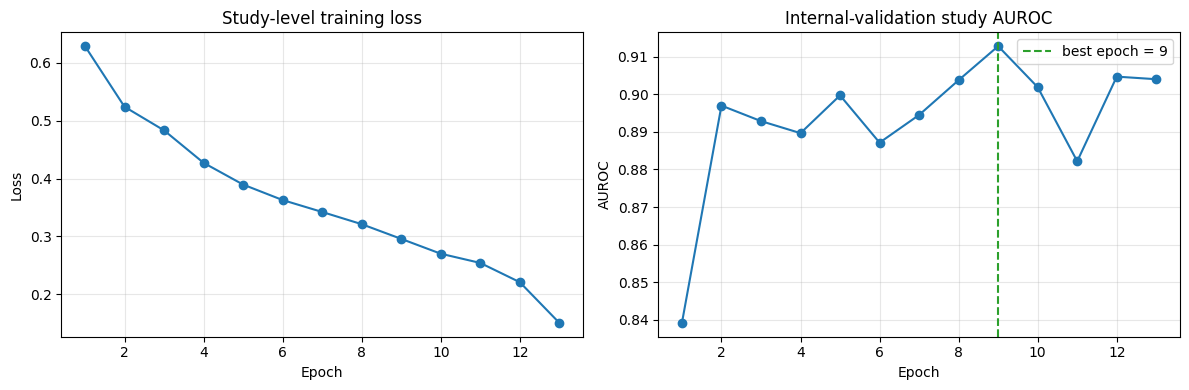

In [7]:
history_frame = pd.DataFrame(history["history"])
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
axes[0].plot(history_frame["epoch"], history_frame["train_loss"], marker="o")
axes[0].set(title="Study-level training loss", xlabel="Epoch", ylabel="Loss")
axes[0].grid(alpha=0.3)

axes[1].plot(history_frame["epoch"], history_frame["validation_monitor"], marker="o")
best_epoch = int(history["best_epoch"])
axes[1].axvline(best_epoch, color="tab:green", linestyle="--", label=f"best epoch = {best_epoch}")
axes[1].set(title="Internal-validation study AUROC", xlabel="Epoch", ylabel="AUROC")
axes[1].legend()
axes[1].grid(alpha=0.3)
plt.tight_layout()
plt.show()

## Handoff

Notebook 06 compares Model B with the frozen embedding baseline on the same internal-validation studies. It does not create a new official-valid result.